In [1]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('./retail-products-classification/train.csv')

le = LabelEncoder()
df['category_encoded'] = le.fit_transform(df['categories'])

df_train, df_val = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df['category_encoded']
)

In [4]:
df_train['description'] = df_train['description'].fillna('').astype(str)
df_val['description'] = df_val['description'].fillna('').astype(str)

In [5]:
text_vectorizer = TfidfVectorizer(max_features=3000)
X_train_text = text_vectorizer.fit_transform(df_train['description'])
X_val_text = text_vectorizer.transform(df_val['description'])

text_clf = LogisticRegression(max_iter=500)
text_clf.fit(X_train_text, df_train['category_encoded'])

y_pred_text = text_clf.predict(X_val_text)

In [13]:
def load_images_features(df_subset, img_dir='train'):
    features = []
    for img_name in df_subset['ImgId']:
        filename = str(img_name) if str(img_name).endswith('.jpg') else f"{img_name}.jpg"
        
        # Перебираємо можливі варіанти шляхів (включно з абсолютними)
        paths_to_try = [
            os.path.join(img_dir, filename),
            os.path.join('..', img_dir, filename),
            os.path.join('multimodal', img_dir, filename),
            os.path.abspath(os.path.join(img_dir, filename))
        ]
        
        img_path = next((p for p in paths_to_try if os.path.exists(p)), None)
        
        if img_path:
            img = Image.open(img_path).convert('L').resize((32, 32))
            features.append(np.array(img).flatten())
        else:
            features.append(np.zeros(32 * 32))
            
    return np.array(features)

X_train_img = load_images_features(df_train, 'train') / 255.0
X_val_img = load_images_features(df_val, 'train') / 255.0

vision_clf = LogisticRegression(max_iter=500)
vision_clf.fit(X_train_img, df_train['category_encoded'])
y_pred_vision = vision_clf.predict(X_val_img)

In [14]:
X_train_fusion = np.hstack([X_train_text.toarray(), X_train_img])
X_val_fusion = np.hstack([X_val_text.toarray(), X_val_img])

fusion_clf = LogisticRegression(max_iter=500)
fusion_clf.fit(X_train_fusion, df_train['category_encoded'])

y_pred_fusion = fusion_clf.predict(X_val_fusion)

                           precision    recall  f1-score   support

               All Beauty       0.59      0.53      0.56       440
          All Electronics       0.58      0.47      0.52       440
               Appliances       0.91      0.84      0.87       440
    Arts, Crafts & Sewing       0.72      0.70      0.71       445
               Automotive       0.64      0.61      0.62       440
                     Baby       0.69      0.71      0.70       440
            Baby Products       0.69      0.55      0.61       440
                   Beauty       0.60      0.57      0.59       441
Cell Phones & Accessories       0.85      0.87      0.86       440
Clothing, Shoes & Jewelry       0.69      0.72      0.71       440
              Electronics       0.77      0.77      0.77       440
   Grocery & Gourmet Food       0.85      0.90      0.87       440
   Health & Personal Care       0.61      0.59      0.60       440
  Industrial & Scientific       0.36      0.58      0.45     

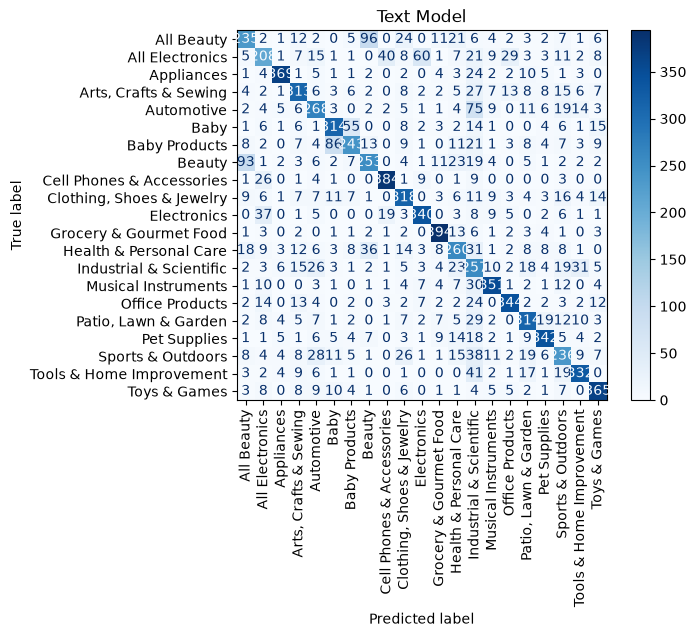

c:\Users\myure\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\myure\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\myure\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

                           precision    recall  f1-score   support

               All Beauty       0.00      0.00      0.00       440
          All Electronics       0.00      0.00      0.00       440
               Appliances       0.00      0.00      0.00       440
    Arts, Crafts & Sewing       0.05      1.00      0.09       445
               Automotive       0.00      0.00      0.00       440
                     Baby       0.00      0.00      0.00       440
            Baby Products       0.00      0.00      0.00       440
                   Beauty       0.00      0.00      0.00       441
Cell Phones & Accessories       0.00      0.00      0.00       440
Clothing, Shoes & Jewelry       0.00      0.00      0.00       440
              Electronics       0.00      0.00      0.00       440
   Grocery & Gourmet Food       0.00      0.00      0.00       440
   Health & Personal Care       0.00      0.00      0.00       440
  Industrial & Scientific       0.00      0.00      0.00     

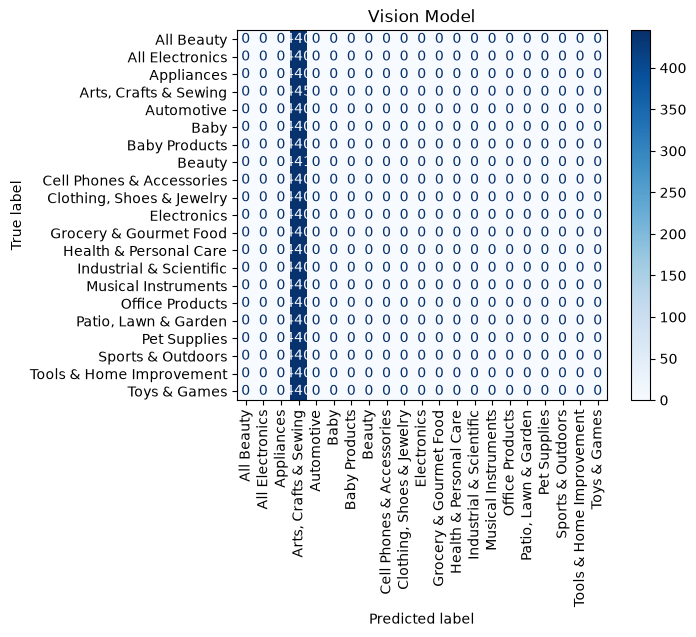

                           precision    recall  f1-score   support

               All Beauty       0.59      0.53      0.56       440
          All Electronics       0.58      0.47      0.52       440
               Appliances       0.91      0.84      0.87       440
    Arts, Crafts & Sewing       0.72      0.70      0.71       445
               Automotive       0.64      0.61      0.62       440
                     Baby       0.69      0.71      0.70       440
            Baby Products       0.69      0.55      0.61       440
                   Beauty       0.60      0.57      0.59       441
Cell Phones & Accessories       0.85      0.87      0.86       440
Clothing, Shoes & Jewelry       0.69      0.72      0.71       440
              Electronics       0.77      0.77      0.77       440
   Grocery & Gourmet Food       0.85      0.90      0.87       440
   Health & Personal Care       0.61      0.59      0.60       440
  Industrial & Scientific       0.36      0.58      0.45     

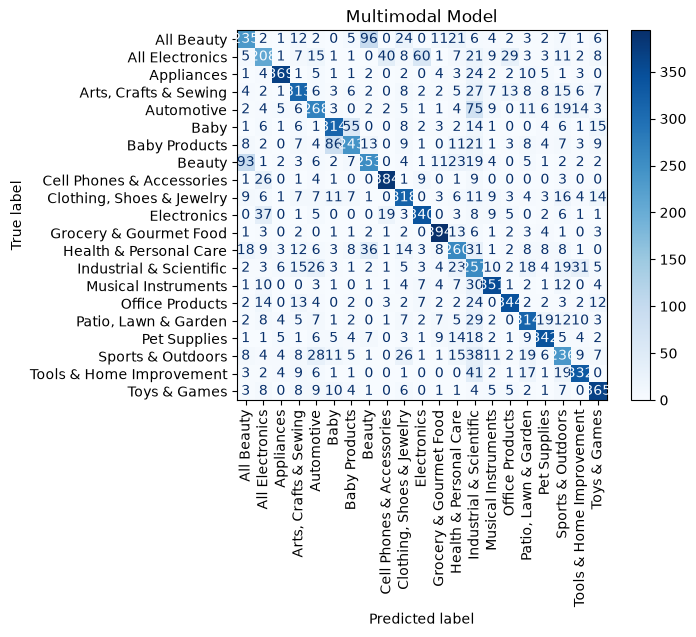

In [15]:
def evaluate(y_true, y_pred, title):
    print(classification_report(y_true, y_pred, target_names=le.classes_))
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
    disp.plot(cmap=plt.cm.Blues)
    plt.title(title)
    plt.xticks(rotation=90)
    plt.show()

evaluate(df_val['category_encoded'], y_pred_text, "Text Model")
evaluate(df_val['category_encoded'], y_pred_vision, "Vision Model")
evaluate(df_val['category_encoded'], y_pred_fusion, "Multimodal Model")